# Лабораторная работа 2. K-means

`Исполнитель`: Александр Сорокин

`Данные`: Economics_of_Cities.csv

Иерархическая кластеризация этих же данных — в лабораторной 1 (`ierarh_clustering.ipynb`)

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, fcluster

plt.style.use('ggplot')

## Данные

Хотим получить те же 46 городов, что в лабораторной 1, иначе сравнение с иерархией будет нечестным. Поэтому повторяем ту же очистку. У Каира и Джакарты вместо значений заглушки −9999 в двух признаках из трёх, такие города удаляем. Подробный разбор выбросов — в лабораторной 1.

`index_col='City'` сразу делает названия городов индексом: в расчёт расстояний они не попадут, но останутся подписями строк.

In [29]:
# sep=";" - разделитель столбцов, decimal="," - разделитель дробной части
df = pd.read_csv('Economics_of_Cities.csv', sep=';', decimal=',', index_col='City')
cols = ['Work', 'Price', 'Salary']

# -9999 - заглушка вместо пропуска: превращаем в NaN и удаляем такие города
df = df.replace(-9999, np.nan).dropna()
print(df.shape)
df.describe().round(1)

(46, 3)


,Work,Price,Salary
count,46.0,46.0,46.0
mean,1879.9,70.1,39.5
std,174.3,21.4,24.8
min,1583.0,30.3,2.7
25%,1745.2,51.8,14.4
50%,1849.0,70.9,43.6
75%,1976.2,81.9,59.7
max,2375.0,115.5,100.0


### Стандартизация

K-means относит город к ближайшему центру по евклидову расстоянию, то есть складывает квадраты разниц по всем признакам. `Work` измеряется в часах (тысячи), `Price` и `Salary` — в индексах (десятки), поэтому без стандартизации расстояние почти целиком определяли бы часы.

Хотим, чтобы каждый признак влиял на расстояние одинаково. `StandardScaler` вычитает из признака среднее и делит на стандартное отклонение, таким образом у всех признаков становится среднее 0 и дисперсия 1. Проверяем это долей, которую каждый признак «забирает» в сумме квадратов расстояний до стандартизации и после.

In [31]:
X = pd.DataFrame(StandardScaler().fit_transform(df), index=df.index, columns=cols)

# вклад признака в расстояние пропорционален его дисперсии
print(f'до стандартизации, % {(df.var() / df.var().sum() * 100).round(1)}\n\n')
print(f'после, % {(X.var() / X.var().sum() * 100).round(1)}')

до стандартизации, % Work      96.6
Price      1.5
Salary     1.9
dtype: float64


после, % Work      33.3
Price     33.3
Salary    33.3
dtype: float64


## Как работает K-means

1. Выбираем k случайных точек — начальные центры кластеров.
2. Каждый город относим к ближайшему центру.
3. Центр каждого кластера пересчитываем как среднее его городов (отсюда «средних» в названии).
4. Повторяем шаги 2–3, пока города не перестанут переходить из кластера в кластер.

Алгоритм минимизирует сумму квадратов расстояний от городов до центров их кластеров (инерция).

В отличие от иерархии, где слияния окончательные, K-means на каждом шаге может перекинуть город в другой кластер. Зато результат зависит от случайного старта, поэтому

- запускаем алгоритм 10 раз и берём лучший запуск по inertia;
- фиксируем случайность, чтобы при перезапуске ноутбука получалось то же самое.

## Выбор числа кластеров

Число k K-means сам не выбирает, его задаём мы. Хотим понять, при каком k кластеры получаются компактными и хорошо отделёнными друг от друга. Для этого обучаем модель для каждого k от 1 до 10 и считаем метрики:

- **inertia** — сумма квадратов расстояний до центров. С ростом k она падает всегда, поэтому ищем «локоть», после которого падение резко замедляется. Колонка `падение inertia` показывает, сколько выиграли, добавив k-й кластер;
- **silhouette** — для каждого города сравнивает расстояние до своего кластера и до ближайшего чужого, от −1 до 1, больше — лучше;
- **davies_bouldin** — отношение разброса внутри кластеров к расстоянию между ними, меньше — лучше;
- **calinski_harabasz** — отношение разброса между кластерами к разбросу внутри, больше — лучше.

При k=1 считается только inertia: остальные метрики сравнивают кластеры между собой, а сравнивать не с чем.

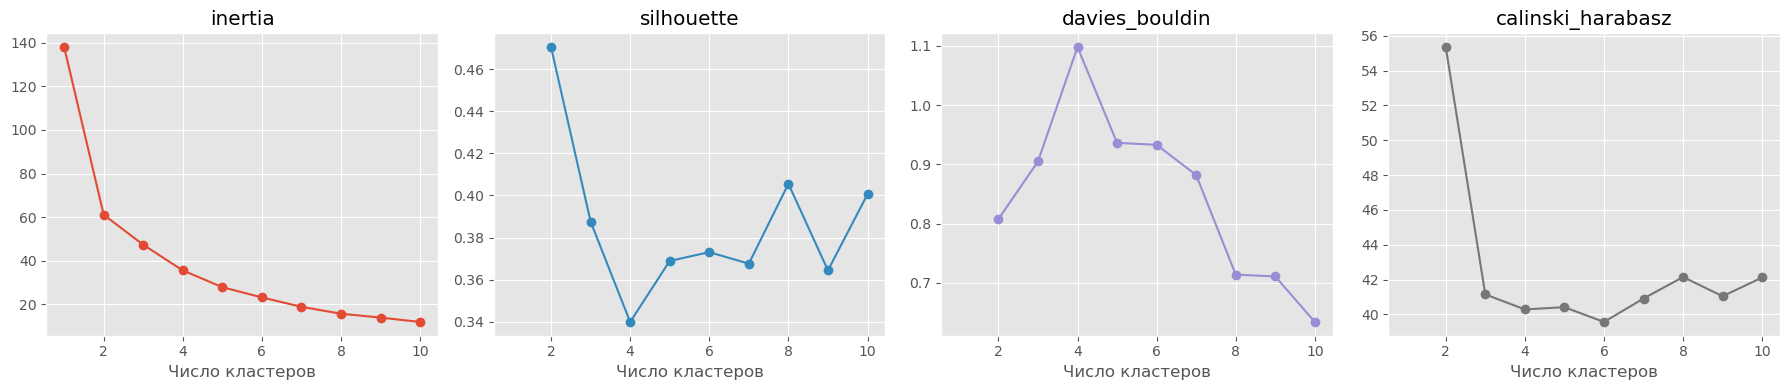

,inertia,падение inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,,
1,138.000,nan,nan,nan,nan
2,61.117,76.883,0.470,0.808,55.351
3,47.361,13.756,0.388,0.905,41.146
4,35.592,11.769,0.340,1.098,40.282
5,27.920,7.672,0.369,0.936,40.412
6,23.213,4.708,0.373,0.933,39.560
7,18.921,4.292,0.368,0.882,40.908
8,15.748,3.173,0.406,0.714,42.142
9,13.977,1.771,0.364,0.711,41.039


In [35]:
def kmeans_metrics(data, k_range=range(1, 11), n_init=10):
    rows = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=n_init, random_state=42).fit(data)
        row = {'k': k, 'inertia': km.inertia_}
        if k > 1:
            row['silhouette'] = silhouette_score(data, km.labels_)
            row['davies_bouldin'] = davies_bouldin_score(data, km.labels_)
            row['calinski_harabasz'] = calinski_harabasz_score(data, km.labels_)
        rows.append(row)
    return pd.DataFrame(rows).set_index('k')


metrics = kmeans_metrics(X)

# по графику на каждую метрику
metrics.plot(subplots=True, layout=(1, 4), figsize=(18, 4), marker='o', legend=False,
             title=list(metrics.columns), xlabel='Число кластеров')
plt.tight_layout()
plt.show()

metrics.insert(1, 'падение inertia', metrics['inertia'].diff().abs())
metrics.style.format(precision=3).background_gradient()

**Все метрики говорят, что кластеров 2**

- инерция падает на 76.9 при переходе от 1 к 2 кластерам, далее кривая равномерная
- силуэт максимальный (0.47) при k=2, 
- Индекс Калински-Харабаша тоже (55.4, при остальных k около 40), 
- Индекс Дэвиса-Болдуина среди небольших k минимальный (0.81). При k=8–10 davies_bouldin снова падает, но это кластеры по 4–6 городов, описывать их нет смысла.

**Лучше 2 кластера**, как и в иерархической кластеризации в лабораторной 1. 

При k=4 метрики хуже всего, но берём 4, потому что так можно сравнить результат с иерархической кластеризацией

## 4 кластера

Хотим, чтобы номер кластера что-то значил и совпадал по смыслу с лабораторной 1, поэтому перенумеруем кластеры по убыванию средней зарплаты

1 — самая высокая

4 — самая низкая.

In [11]:
def by_salary(labels):
    # считает среднюю зарплату в каждом кластере и сортирует по убыванию
    
    # получаем старые метки в нужном порядке
    order = df.groupby(labels)['Salary'].mean().sort_values(ascending=False).index
    
    # строит словарь «старая метка → новый номер»
    mapping = {old: str(new) for new, old in enumerate(order, start=1)}
    
    return pd.Series(labels, index=df.index).map(mapping) # заменяет метки по словарю
# Номера делаем строками,
# чтобы на графиках seaborn раскрашивал кластеры как категории, 
# а не градиентом как числа.
# Эта функция пригодится для сравнения с иерархическим алгоритмом.

km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)

res = df.copy()  # исходные значения + метки кластеров, X не трогаем
res['kmeans'] = by_salary(km4.labels_)

### Центры кластеров

Центры, которые нашёл K-means (`km4.cluster_centers_`), лежат в стандартизованном пространстве. Можно вернуть их в исходные единицы через `inverse_transform`, но проще посчитать средние по кластерам в исходной таблице

In [12]:
prof = res.groupby('kmeans')[cols].mean().round(1)
prof['городов'] = res['kmeans'].value_counts()
prof

,Work,Price,Salary,городов
kmeans,,,,
1,1763.8,104.6,67.6,8
2,1801.2,75.8,55.0,17
3,1855.5,50.8,16.6,11
4,2133.5,54.2,16.1,10


In [7]:
# состав кластеров
res.reset_index().groupby('kmeans')['City'].agg(', '.join).to_frame('города')

,города
kmeans,
1,"Copenhagen, Geneva, Helsinki, Madrid, Oslo, St..."
2,"Amsterdam, Brussels, Chicago, Dublin, Dusseldo..."
3,"Athens, Buenos_Aires, Johannesburg, Lagos, Lis..."
4,"Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lump..."


1. **Самые дорогие (8 городов).** Цены 104.6, зарплаты 67.6, рабочий год самый короткий (1764 ч).
2. **Развитые (17).** Цены и зарплаты выше среднего (75.8 и 55.0).
3. **Небогатые с обычным рабочим годом (11).** Зарплаты около 16.6, часы 1856 — около среднего по всем городам (1880).
4. **Небогатые с длинным рабочим годом (10).** Зарплаты как у кластера 3 (16.1), но работают 2134 ч, почти на 280 часов больше.

Кластеры 3 и 4 по ценам и зарплатам одинаковые и различаются только продолжительностью рабочего года. Те же четыре группы получились у иерархической кластеризации в лабораторной 1.

## Сравнение с иерархической кластеризацией

Чтобы понять, нашли ли два разных метода одни и те же группы заново строим иерархию на тех же стандартизованных данных и тоже на 4 кластера (как в лабораторной 1) и перенумеровываем его той же функцией `by_salary`, чтобы номера кластеров означали одно и то же.

`pd.crosstab` показывает, сколько городов из каждого кластера иерархии попало в каждый кластер K-means. Если методы согласны, почти все города стоят на диагонали.

In [21]:
ierarh = fcluster(linkage(X, method='ward'), 4, criterion='maxclust')
res['ierarh'] = by_salary(ierarh)

pd.crosstab(res['ierarh'], res['kmeans'], rownames=['ierarh'], colnames=['K-means'])

K-means,1,2,3,4
ierarh,,,,
1,6,0,0,0
2,2,17,0,0
3,0,0,7,0
4,0,0,4,10


In [22]:
# города, которые методы отнесли по-разному, и их силуэт в каждом методе
res['силуэт ierarh'] = silhouette_samples(X, res['ierarh']).round(2)
res['силуэт K-means'] = silhouette_samples(X, res['kmeans']).round(2)

diff = res[res['ierarh'] != res['kmeans']]
diff

,Work,Price,Salary,kmeans,ward,ierarh,силуэт ierarh,силуэт K-means
City,,,,,,,,
Buenos_Aires,1971.0,56.1,12.5,3,4,4,0.06,0.23
Copenhagen,1717.0,91.3,62.9,1,2,2,0.22,-0.12
Johannesburg,1945.0,51.1,24.0,3,4,4,-0.22,0.37
Madrid,1710.0,93.8,50.0,1,2,2,0.26,-0.15
Mexico_City,1944.0,49.8,5.7,3,4,4,-0.10,0.37
Nairobi,1958.0,45.0,5.8,3,4,4,-0.03,0.31


Смотрим где на графике лежат спорные города. Обводим и подписываем только города, где методы разошлись, у остальных цвет на обеих картинках одинаковый.

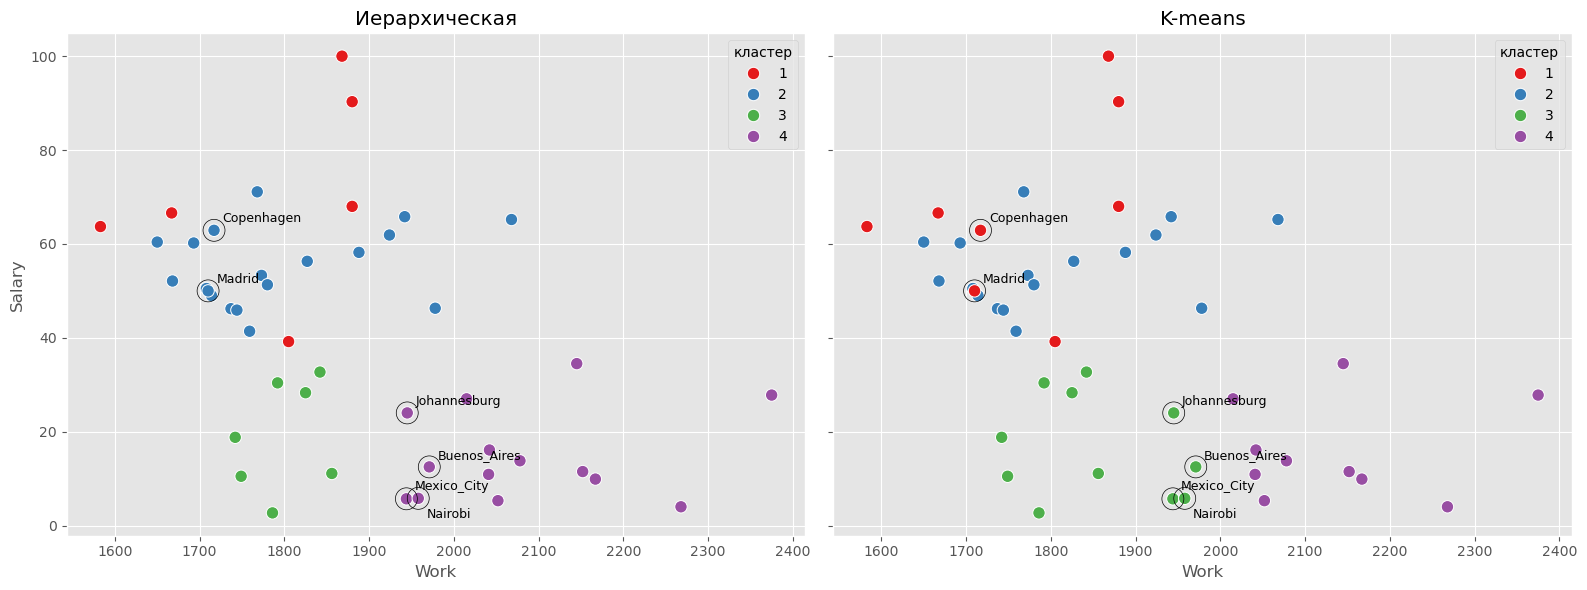

In [27]:
order = ['1', '2', '3', '4']  # порядок кластеров, чтобы цвета не прыгали между графиками

# создаём картинку из двух графиков в ряд
# sharey=True - общая ось y, чтобы зарплаты на обоих графиках были в одной шкале
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# zip складывает три списка поэлементно, поэтому цикл проходит 2 раза:
#   1-й раз: ax = левый график,  col = 'ierarh', title = 'Иерархическая'
#   2-й раз: ax = правый график, col = 'kmeans', title = 'K-means'
for ax, col, title in zip(axes, ['ierarh', 'kmeans'], ['Иерархическая', 'K-means']):
    
    # hue_order и palette - одинаковые цвета кластеров на обоих графиках, s - размер точек
    sns.scatterplot(data=res, x='Work', y='Salary', hue=col, hue_order=order,
                    palette='Set1', s=80, ax=ax)

    # поверх рисуем пустые чёрные кружки вокруг городов, где методы разошлись (таблица diff)
    ax.scatter(diff['Work'], diff['Salary'], s=250, facecolors='none', edgecolors='black')

    # проходим по спорным городам
    for city, row in diff.iterrows():
        # сдвиг подписи от точки в пикселях; Найроби почти в той же точке, что Мехико, поэтому его подпись вниз
        shift = (6, -14) if city == 'Nairobi' else (6, 6)
        # пишем название города рядом с его точкой (Work, Salary) со сдвигом shift
        ax.annotate(city, (row['Work'], row['Salary']), fontsize=9,
                    xytext=shift, textcoords='offset points')

    ax.set_title(title)            # заголовок графика
    ax.legend(title='кластер')     # легенда

plt.tight_layout()  # подгоняем отступы, чтобы графики и подписи не налезали друг на друга
plt.show()          # показываем картинку

Разошлись шесть городов:

- **Копенгаген и Мадрид:** у иерархии в кластере 2, у K-means в кластере 1. На графике `Work × Salary` их почти не отличить от соседей, потому что спорят методы по третьему признаку, `Price`. У K-means силуэт у них отрицательный (−0.12 и −0.15), они находятся не в самом подходящем кластере.

- **Буэнос-Айрес, Йоханнесбург, Мехико, Найроби:** у иерархии в кластере 4, у K-means в кластере 3. Работают они 1944–1971 ч — между средними кластеров 3 (1856) и 4 (2134). У иерархии у трёх из них силуэт отрицательный, у K-means у всех четырёх положительный (0.23–0.37).

Методы спорят только о городах на границе между кластерами.

Сравниваем качество разбиений одним числом — средним силуэтом — и считаем, сколько городов в каждом методе сидят в «чужом» кластере (силуэт меньше 0).

In [30]:
pd.DataFrame({
    'средний силуэт': [silhouette_score(X, res['ierarh']), silhouette_score(X, res['kmeans'])],
    'городов с силуэтом < 0': [(res['силуэт ierarh'] < 0).sum(), (res['силуэт K-means'] < 0).sum()],
}, index=['ierarh', 'K-means']).round(3)

,средний силуэт,городов с силуэтом < 0
ierarh,0.355,3
K-means,0.340,3


## Выводы

46 городов (Каир и Джакарта удалены из-за заглушек −9999), признаки стандартизованы. 

Без стандартизации `Work` забирал бы 96.6% расстояния, после неё каждый признак даёт по 33.3%.

Все метрики K-means (силуэт 0.47, calinski_harabasz 55.4, davies_bouldin 0.81) указывают на 2 кластера: богатые и бедные города. 

Цены и зарплаты сильно связаны и вместе дают главное различие. Взял 4 кластера, чтобы сравнить с иерархией и получить более подробное описание: на 4 кластерах бедные города делятся уже не по деньгам, а по продолжительности рабочего года.

- дорогие города (8)
- развитые (17)
- небогатые с обычным рабочим годом (11) 
- небогатые с длинным рабочим годом (10)

K-means и иерархия совпали на 40 городах из 46, средний силуэт почти одинаковый (0.340 у K-means и 0.355 у иерархии), у каждого метода по 3 города с отрицательным силуэтом. 


Разошлись только пограничные города: Копенгаген и Мадрид по ценам, Буэнос-Айрес, Йоханнесбург, Мехико и Найроби по часам работы. Два разных метода нашли одни и те же четыре группы, значит, такая структура в данных устойчивая.